In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import mnist

import numpy as np
import matplotlib.pyplot as plt

from typing import Tuple, Dict
from sklearn.model_selection import train_test_split
tf.config.list_physical_devices('GPU')

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

In [2]:
# Load MNIST dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Preserve raw test data for integration testing
x_test_raw = x_test.copy()
y_test_raw = y_test.copy()

# Split training data into training and validation sets
x_train, x_val, y_train, y_val = train_test_split(
    x_train, y_train,
    test_size=10000,
    random_state=42,
    stratify=y_train
)

print("Training set:", x_train.shape)
print("Validation set:", x_val.shape)
print("Test set:", x_test.shape)

Training set: (50000, 28, 28)
Validation set: (10000, 28, 28)
Test set: (10000, 28, 28)


In [3]:
# Flatten and normalize
x_train = x_train.reshape(-1, 28 * 28).astype('float32') / 255.0
x_val = x_val.reshape(-1, 28 * 28).astype('float32') / 255.0
x_test = x_test.reshape(-1, 28 * 28).astype('float32') / 255.0

# Convert labels to one-hot encoding
y_train = tf.keras.utils.to_categorical(y_train, 10)
y_val = tf.keras.utils.to_categorical(y_val, 10)
y_test = tf.keras.utils.to_categorical(y_test, 10)

print("Training set:", x_train.shape, y_train.shape)
print("Validation set:", x_val.shape, y_val.shape)
print("Test set:", x_test.shape, y_test.shape)

Training set: (50000, 784) (50000, 10)
Validation set: (10000, 784) (10000, 10)
Test set: (10000, 784) (10000, 10)


In [4]:
def create_convnet(
        input_shape: int, output_units: int, learning_rate: float = 0.001
) -> models.Sequential:
    """Creates a convolutional neural network (ConvNet) model."""

    model = models.Sequential()
    model.add(layers.Input(shape=(input_shape,)))
    model.add(layers.Reshape((28, 28, 1))) # Reshape for Conv2D

    model.add(layers.Conv2D(32, (3, 3), activation='relu'))
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Conv2D(64, (3, 3), activation='relu'))
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Flatten())
    model.add(layers.Dense(64, activation='relu'))
    model.add(layers.Dense(output_units, activation='softmax'))

    optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate)
    model.compile(optimizer=optimizer, loss='categorical_crossentropy',
                  metrics=['accuracy'], jit_compile=False)

    return model

In [5]:
def train_model(
        x_train: tf.Tensor,
        y_train: tf.Tensor,
        x_val: tf.Tensor,
        y_val: tf.Tensor,
        learning_rate: float = 0.001,
        batch_size: int = 128,
        epochs: int = 6
) -> Tuple[models.Sequential, Dict[str, list]]:

    """Creates, compiles, and trains the ConvNet model."""

    input_shape = x_train.shape[1]
    output_units = y_train.shape[1]

    model = create_convnet(input_shape, output_units, learning_rate)

    # Evaluate the model before training
    initial_train_loss, initial_train_accuracy = model.evaluate(x_train, y_train, verbose=0)
    initial_val_loss, initial_val_accuracy = model.evaluate(x_val, y_val, verbose=0)

    print(f"Initial Training Loss (Untrained): {initial_train_loss:.4f}")
    print(f"Initial Training Accuracy (Untrained): {initial_train_accuracy:.4f}")
    print(f"Initial Validation Loss (Untrained): {initial_val_loss:.4f}")
    print(f"Initial Validation Accuracy (Untrained): {initial_val_accuracy:.4f}")

    history = model.fit(
        x_train, y_train, batch_size=batch_size, epochs=epochs,
        validation_data=(x_val, y_val)
    )

    # Include initial loss and accuracy before training (epoch 0)
    history.history['loss'].insert(0, initial_train_loss)
    history.history['val_loss'].insert(0, initial_val_loss)
    history.history['accuracy'].insert(0, initial_train_accuracy)
    history.history['val_accuracy'].insert(0, initial_val_accuracy)

    return model, history.history

In [6]:
import pandas as pd

# Hyperparameter configurations
configurations = [
    (0.001, 128, 6),
    (0.001, 128, 15),
    (0.0005, 64, 20),
    (0.0001, 128, 20),
    (0.0001, 128, 30),
    (0.0002, 128, 20)
]

trained_models = {}
training_histories = {}
results = []

thresholds = [0, 0.5, 0.7, 0.8, 0.9, 0.95, 0.97,
              0.99, 0.995, 0.999, 0.9995, 0.9999, 0.99999]

target_accuracy = 0.999
val_labels = np.argmax(y_val, axis=1)

for i, (lr, batch, ep) in enumerate(configurations, start=1):

    print(f"\nTraining Model {i}")
    print(f"Learning rate: {lr}, Batch size: {batch}, Epochs: {ep}")

    # Set random seed for reproducibility
    tf.keras.utils.set_random_seed(42)

    # Train model
    model, history = train_model(
        x_train, y_train, x_val, y_val,
        learning_rate=lr,
        batch_size=batch,
        epochs=ep
    )

    # Store trained model and training history
    trained_models[i] = model
    training_histories[i] = history

    # Evaluate validation performance
    val_loss, val_accuracy = model.evaluate(x_val, y_val, verbose=0)

    val_probabilities = model.predict(x_val, verbose=0)
    val_predictions = np.argmax(val_probabilities, axis=1)
    val_confidence = np.max(val_probabilities, axis=1)

    # Find the lowest threshold satisfying the target accuracy
    selected_threshold = np.nan
    accepted_accuracy = np.nan
    coverage = 0.0
    incorrect_accepted = 0

    for threshold in thresholds:

        accepted = val_confidence >= threshold

        if not np.any(accepted):
            continue

        accuracy = np.mean(
            val_predictions[accepted] == val_labels[accepted]
        )

        if accuracy >= target_accuracy:
            selected_threshold = threshold
            accepted_accuracy = accuracy
            coverage = np.mean(accepted)
            incorrect_accepted = np.sum(
                val_predictions[accepted] != val_labels[accepted]
            )
            break

    # Store model results
    results.append({
        "Model": i,
        "Learning Rate": lr,
        "Batch Size": batch,
        "Epochs": ep,
        "Training Accuracy": history['accuracy'][-1],
        "Training Loss": history['loss'][-1],
        "Validation Accuracy": val_accuracy,
        "Validation Loss": val_loss,
        "Threshold": selected_threshold,
        "Accepted Accuracy": accepted_accuracy,
        "Coverage": coverage,
        "Incorrectly Accepted": incorrect_accepted
    })


Training Model 1
Learning rate: 0.001, Batch size: 128, Epochs: 6


2026-11-26 12:00:30.100662: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M4
2026-11-26 12:00:30.100685: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2026-11-26 12:00:30.100692: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.33 GB
2026-11-26 12:00:30.100713: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-11-26 12:00:30.100722: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)
2026-11-26 12:00:30.374808: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


Initial Training Loss (Untrained): 2.3057
Initial Training Accuracy (Untrained): 0.1291
Initial Validation Loss (Untrained): 2.3061
Initial Validation Accuracy (Untrained): 0.1290
Epoch 1/6
391/391 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step - accuracy: 0.9222 - loss: 0.2636 - val_accuracy: 0.9733 - val_loss: 0.0909
Epoch 2/6
391/391 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.9774 - loss: 0.0757 - val_accuracy: 0.9812 - val_loss: 0.0641
Epoch 3/6
391/391 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.9821 - loss: 0.0604 - val_accuracy: 0.9831 - val_loss: 0.0602
Epoch 4/6
391/391 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.9845 - loss: 0.0538 - val_accuracy: 0.9840 - val_loss: 0.0623
Epoch 5/6
391/391 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.9857 - loss: 0.0506 - val_accuracy: 0.9854 - val_loss: 0.0669
Epoch 6/6
391/391 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.9867 - loss: 0.0515 - val_accuracy: 0.9843 - val_loss: 0.0790

Training Model 2
Learning rate: 0.001, Batch size: 

In [7]:
# Compare all six models
results_df = pd.DataFrame(results)

display(results_df.round(6))

# Select models satisfying the minimum accepted accuracy of 99.9%
eligible_models = results_df[
    results_df["Accepted Accuracy"] >= target_accuracy
]

if eligible_models.empty:
    raise ValueError("No model satisfies the target accepted accuracy.")

# Select the model with the highest coverage
best_result = eligible_models.sort_values(
    by=["Coverage", "Accepted Accuracy", "Validation Loss"],
    ascending=[False, False, True]
).iloc[0]

# Retrieve the selected model and its training history
best_model_id = int(best_result["Model"])

model = trained_models[best_model_id]
history = training_histories[best_model_id]

best_threshold = float(best_result["Threshold"])
learning_rate = float(best_result["Learning Rate"])
batch_size = int(best_result["Batch Size"])
epochs = int(best_result["Epochs"])

# Display the selected model's performance
print(f"\nSelected Model: {best_model_id}")
print(f"Learning Rate: {learning_rate}")
print(f"Batch Size: {batch_size}")
print(f"Epochs: {epochs}")
print(f"Validation Accuracy: {best_result['Validation Accuracy']:.4%}")
print(f"Validation Loss: {best_result['Validation Loss']:.4f}")
print(f"Confidence Threshold: {best_threshold}")
print(f"Accepted Accuracy: {best_result['Accepted Accuracy']:.4%}")
print(f"Coverage: {best_result['Coverage']:.4%}")
print(f"Incorrectly Accepted: {int(best_result['Incorrectly Accepted'])}")

,Model,Learning Rate,Batch Size,Epochs,Training Accuracy,Training Loss,Validation Accuracy,Validation Loss,Threshold,Accepted Accuracy,Coverage,Incorrectly Accepted
0,1,0.0010,128,6,0.98668,0.051508,0.9843,0.079020,NaN,NaN,0.0000,0
1,2,0.0010,128,15,0.98158,1.137578,0.9777,2.226531,NaN,NaN,0.0000,0
2,3,0.0005,64,20,0.98602,0.551430,0.9811,1.298826,NaN,NaN,0.0000,0
3,4,0.0001,128,20,0.98762,0.042062,0.9823,0.065889,0.9995,0.999167,0.7206,6
4,5,0.0001,128,30,0.99064,0.033585,0.9828,0.072567,0.9999,0.999333,0.7493,5
5,6,0.0002,128,20,0.99082,0.032629,0.9831,0.079590,0.9999,0.999156,0.8290,7



Selected Model: 6
Learning Rate: 0.0002
Batch Size: 128
Epochs: 20
Validation Accuracy: 98.3100%
Validation Loss: 0.0796
Confidence Threshold: 0.9999
Accepted Accuracy: 99.9156%
Coverage: 82.9000%
Incorrectly Accepted: 7


In [9]:
# Evaluate the selected model on the test dataset
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4%}")

# Generate test predictions and confidence scores
test_probabilities = model.predict(x_test, verbose=0)

test_predictions = np.argmax(test_probabilities, axis=1)
test_confidence = np.max(test_probabilities, axis=1)
test_labels = np.argmax(y_test, axis=1)

# Apply the selected confidence threshold
accepted = test_confidence >= best_threshold

# Evaluate confidence-based classification
accepted_accuracy = np.mean(
    test_predictions[accepted] == test_labels[accepted]
) if np.any(accepted) else np.nan

coverage = np.mean(accepted)

print(f"\nConfidence Threshold: {best_threshold}")
print(f"Accepted Accuracy: {accepted_accuracy:.4%}")
print(f"Coverage: {coverage:.4%}")
print("Correctly Accepted:", np.sum(accepted & (test_predictions == test_labels)))
print("Incorrectly Accepted:", np.sum(accepted & (test_predictions != test_labels)))
print("Skipped:", np.sum(~accepted))

Test Loss: 0.0558
Test Accuracy: 98.6200%

Confidence Threshold: 0.9999
Accepted Accuracy: 99.9401%
Coverage: 83.4900%
Correctly Accepted: 8344
Incorrectly Accepted: 5
Skipped: 1651


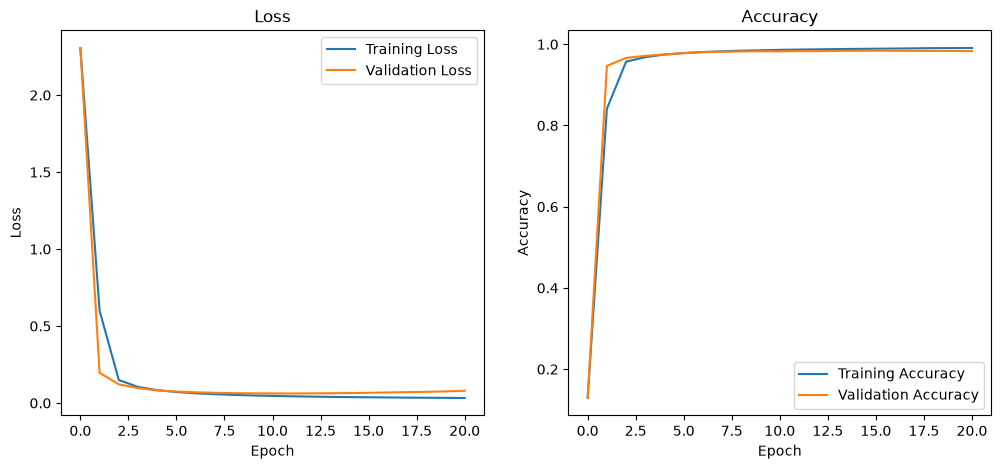

In [10]:
def plot_training_history(history: Dict[str, list]) -> None:
    """Plots training and validation loss and accuracy from the history dictionary."""

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(history['loss'], label='Training Loss')
    plt.plot(history['val_loss'], label='Validation Loss')
    plt.title('Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history['accuracy'], label='Training Accuracy')
    plt.plot(history['val_accuracy'], label='Validation Accuracy')
    plt.title('Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()

    plt.show()


plot_training_history(history)

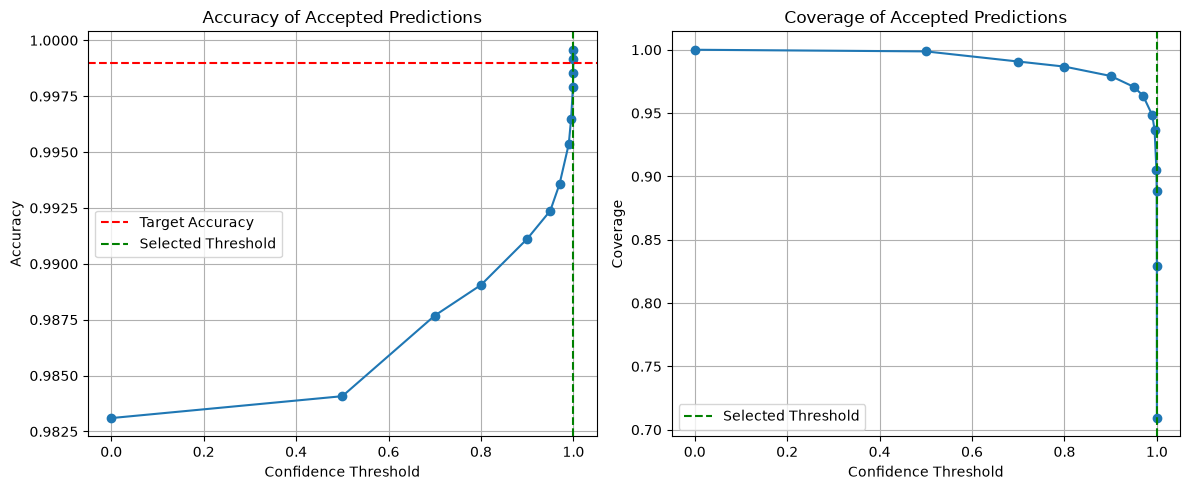

In [11]:
# Generate validation predictions for the selected model
val_probabilities = model.predict(x_val, verbose=0)
val_predictions = np.argmax(val_probabilities, axis=1)
val_confidence = np.max(val_probabilities, axis=1)
val_labels = np.argmax(y_val, axis=1)

accuracies = []
coverages = []

# Evaluate different confidence thresholds
for threshold in thresholds:
    val_accepted = val_confidence >= threshold

    accuracy = np.mean(
        val_predictions[val_accepted] == val_labels[val_accepted]
    ) if val_accepted.any() else np.nan

    accuracies.append(accuracy)
    coverages.append(np.mean(val_accepted))

# Plot accepted accuracy and coverage
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(thresholds, accuracies, marker='o')
plt.axhline(target_accuracy, color='red', linestyle='--', label='Target Accuracy')
plt.axvline(best_threshold, color='green', linestyle='--', label='Selected Threshold')
plt.title('Accuracy of Accepted Predictions')
plt.xlabel('Confidence Threshold')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(thresholds, coverages, marker='o')
plt.axvline(best_threshold, color='green', linestyle='--', label='Selected Threshold')
plt.title('Coverage of Accepted Predictions')
plt.xlabel('Confidence Threshold')
plt.ylabel('Coverage')
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

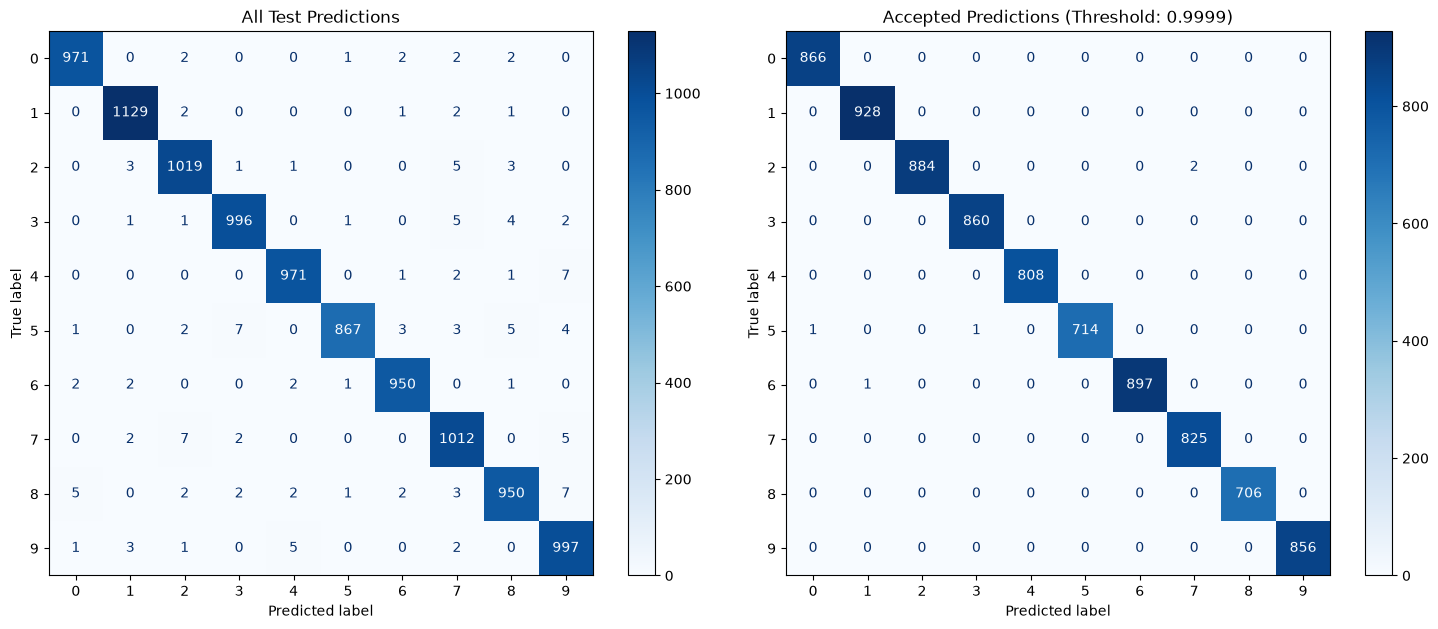

In [12]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Confusion matrix for all test predictions
cm = confusion_matrix(
    test_labels,
    test_predictions,
    labels=np.arange(10)
)

# Confusion matrix for accepted test predictions
cm_accepted = confusion_matrix(
    test_labels[accepted],
    test_predictions[accepted],
    labels=np.arange(10)
)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=np.arange(10)
).plot(cmap='Blues', ax=axes[0])

axes[0].set_title('All Test Predictions')

ConfusionMatrixDisplay(
    confusion_matrix=cm_accepted,
    display_labels=np.arange(10)
).plot(cmap='Blues', ax=axes[1])

axes[1].set_title(f'Accepted Predictions (Threshold: {best_threshold})')

plt.tight_layout()
plt.show()

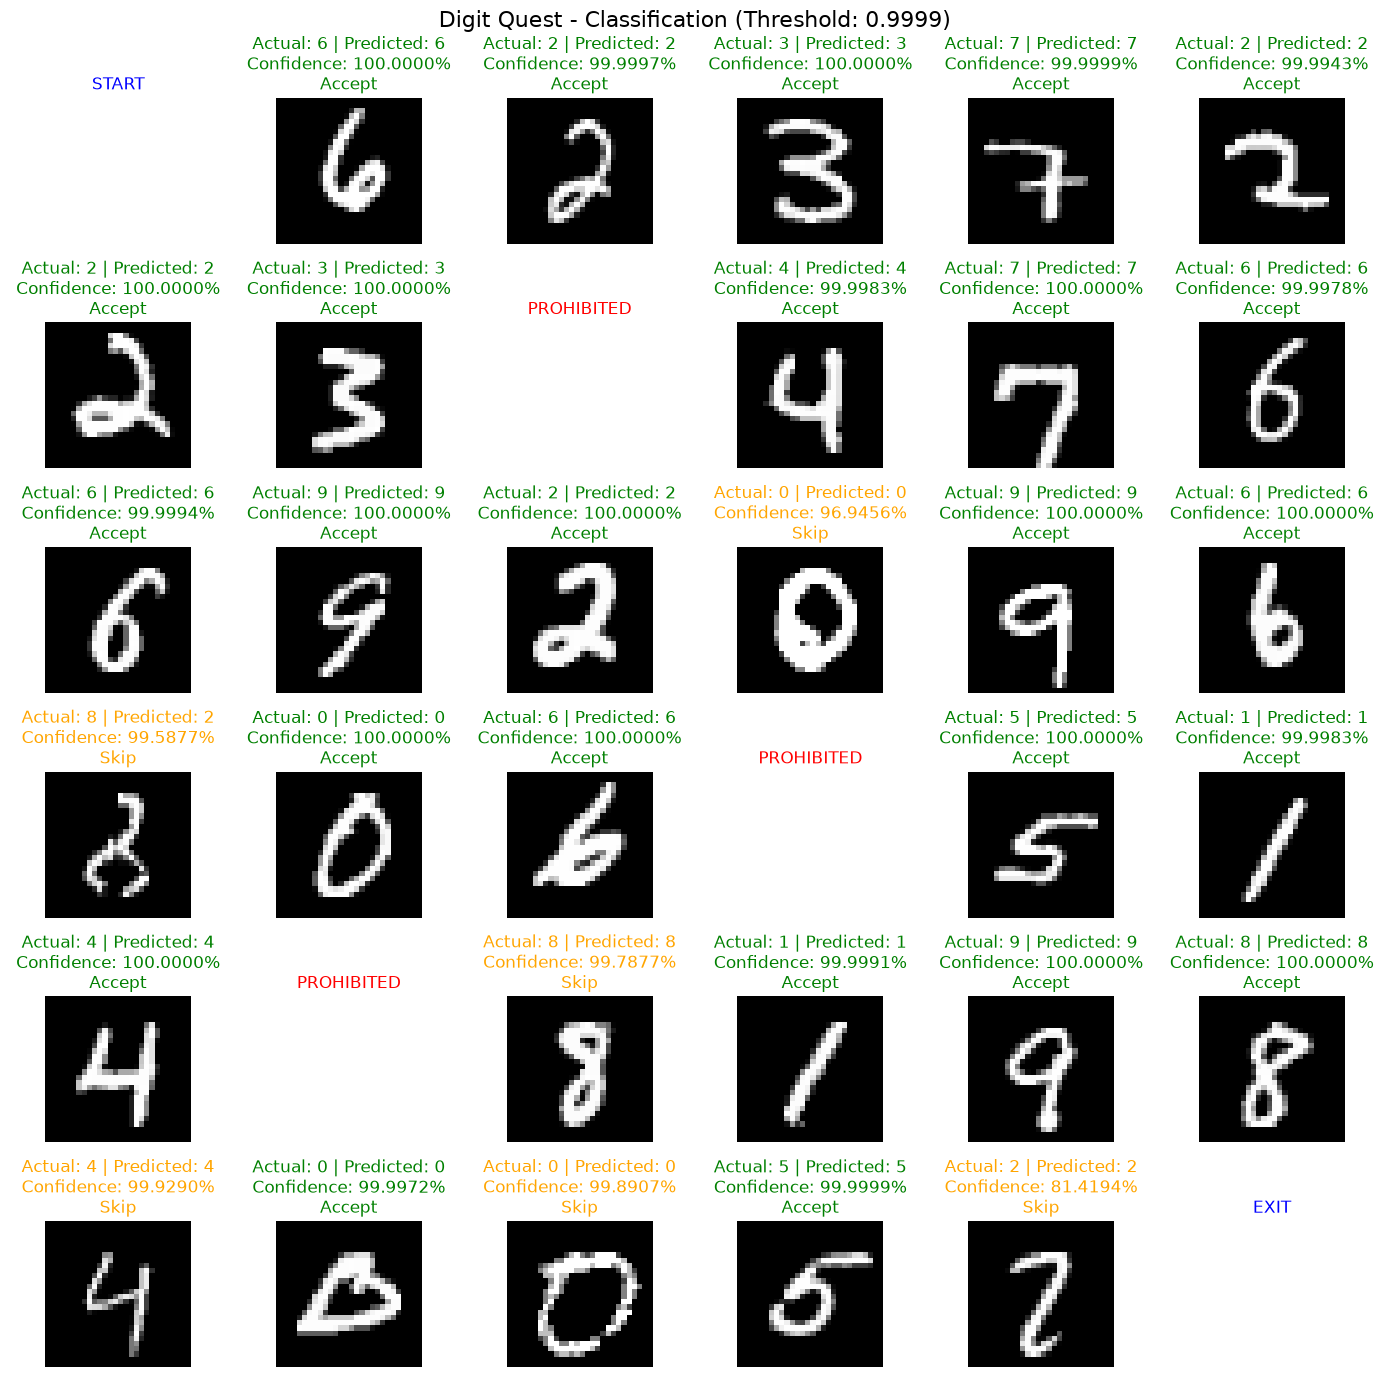

Total Digits: 31
Correctly Classified: 30
Misclassified: 1
Accepted: 25
Skipped: 6
Correctly Accepted: 25
Incorrectly Accepted: 0

Grid Accuracy: 96.7742%
Accepted Accuracy: 100.0000%
Coverage: 80.6452%


In [13]:
# Define grid structure
grid_size = 6
start = (0, 0)
exit_cell = (5, 5)
prohibited = [(1, 2), (3, 3), (4, 1)]

# Randomly select 31 MNIST test images
indices = np.random.choice(len(x_test), 31, replace=False)

fig, axes = plt.subplots(grid_size, grid_size, figsize=(14, 14))

i = 0

for row in range(grid_size):
    for col in range(grid_size):

        ax = axes[row, col]
        ax.axis('off')

        if (row, col) == start:
            ax.set_title('START', color='blue')

        elif (row, col) == exit_cell:
            ax.set_title('EXIT', color='blue')

        elif (row, col) in prohibited:
            ax.set_title('PROHIBITED', color='red')

        else:
            index = indices[i]

            actual = test_labels[index]
            predicted = test_predictions[index]
            confidence = test_confidence[index]

            # Apply confidence threshold
            if confidence >= best_threshold:
                decision = 'Accept'
                color = 'green' if actual == predicted else 'red'
            else:
                decision = 'Skip'
                color = 'orange'

            ax.imshow(x_test[index].reshape(28, 28), cmap='gray')

            ax.set_title(
                f"Actual: {actual} | Predicted: {predicted}\n"
                f"Confidence: {confidence:.4%}\n"
                f"{decision}",
                color=color
            )

            i += 1

plt.suptitle(
    f'Digit Quest - Classification (Threshold: {best_threshold})',
    fontsize=16
)

plt.tight_layout()
plt.show()

# Evaluate classification performance on the generated grid
grid_correct = test_predictions[indices] == test_labels[indices]
grid_accepted = test_confidence[indices] >= best_threshold

print("Total Digits:", len(indices))
print("Correctly Classified:", np.sum(grid_correct))
print("Misclassified:", np.sum(~grid_correct))
print("Accepted:", np.sum(grid_accepted))
print("Skipped:", np.sum(~grid_accepted))
print("Correctly Accepted:", np.sum(grid_accepted & grid_correct))
print("Incorrectly Accepted:", np.sum(grid_accepted & ~grid_correct))

print(f"\nGrid Accuracy: {np.mean(grid_correct):.4%}")
print(f"Accepted Accuracy: {np.mean(grid_correct[grid_accepted]) if grid_accepted.any() else np.nan:.4%}")
print(f"Coverage: {np.mean(grid_accepted):.4%}")

In [15]:
# Evaluate classification across 10 random grids
grid_results = []

for run in range(1, 11):

    indices = np.random.choice(len(x_test), 31, replace=False)

    grid_correct = test_predictions[indices] == test_labels[indices]
    grid_accepted = test_confidence[indices] >= best_threshold

    grid_results.append({
        "Run": run,
        "Correctly Classified": np.sum(grid_correct),
        "Misclassified": np.sum(~grid_correct),
        "Correctly Accepted": np.sum(grid_accepted & grid_correct),
        "Incorrectly Accepted": np.sum(grid_accepted & ~grid_correct),
        "Skipped": np.sum(~grid_accepted)
    })

# Create results table
grid_results_df = pd.DataFrame(grid_results).set_index("Run")

# Add total results
grid_results_df.loc["Total"] = grid_results_df.sum()

display(grid_results_df)

# Calculate overall performance
total = grid_results_df.loc["Total"]

total_accepted = total['Correctly Accepted'] + total['Incorrectly Accepted']

print(f"Overall Accuracy: {total['Correctly Classified'] / 310:.4%}")
print(f"Accepted Accuracy: {total['Correctly Accepted'] / total_accepted:.4%}" if total_accepted else "Accepted Accuracy: N/A")
print(f"Coverage: {total_accepted / 310:.4%}")

,Correctly Classified,Misclassified,Correctly Accepted,Incorrectly Accepted,Skipped
Run,,,,,
1,31,0,28,0,3
2,29,2,21,0,10
3,31,0,25,0,6
4,30,1,27,0,4
5,31,0,26,0,5
6,31,0,25,0,6
7,31,0,27,0,4
8,31,0,26,0,5
9,31,0,27,0,4


Overall Accuracy: 98.3871%
Accepted Accuracy: 100.0000%
Coverage: 82.5806%


In [16]:
import json

# Save the selected ConvNet model
model.save("digit_classifier.keras")

# Save the selected confidence threshold
with open("classifier_config.json", "w") as file:
    json.dump({"confidence_threshold": float(best_threshold)}, file)

print(f"Model {best_model_id} saved successfully.")
print(f"Confidence Threshold: {best_threshold}")

Model 6 saved successfully.
Confidence Threshold: 0.9999
